# OpenCV 高斯差分：从模糊图像中提取数字 1、2、3

生成三个数字，模拟高斯模糊，再对同一幅模糊图像做两个尺度的高斯滤波：

$$I_{\mathrm{DoG}} = (I * G_{\sigma_1}) - (I * G_{\sigma_2}),\quad \sigma_2>\sigma_1.$$

最后通过相对阈值、闭运算、连通区域面积筛选和填洞得到二值数字。
**DoG 是特征增强；二值结果是分割结果，不等于恢复模糊前的精确像素。**


OpenCV version: 4.13.0


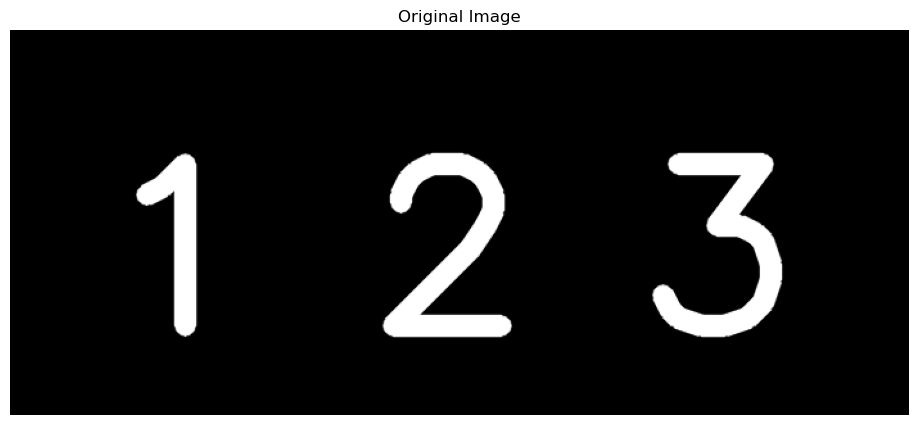

In [1]:
# 功能：生成数字 1、2、3，并用 OpenCV 高斯差分提取模糊图中的数字区域。
# 方法：高斯模糊 → 浮点双尺度高斯滤波相减 → 阈值分割 → 闭运算、面积筛选和填洞。
# 注意事项：按顺序运行；sigma 单位为像素；浮点差分保留负值；保留所有满足面积条件的区域。
# 二值分割不等同于反卷积，也不执行数字识别；依赖 cv2、NumPy 和 Matplotlib。
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)

# 创建黑色背景
img = np.zeros((300, 700), dtype=np.uint8)

# 绘制白色数字 1、2、3
font = cv2.FONT_HERSHEY_SIMPLEX
cv2.putText(img, "1", (70, 230), font, 6, 255, 15, cv2.LINE_AA)
cv2.putText(img, "2", (280, 230), font, 6, 255, 15, cv2.LINE_AA)
cv2.putText(img, "3", (490, 230), font, 6, 255, 15, cv2.LINE_AA)

plt.figure(figsize=(12, 5))
plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")
plt.show()

## 1. 构造模糊输入

保留原有的高斯模糊设置：核大小为 21×21，标准差为 5 像素，不额外添加随机噪声。
将模糊图转换为 0～1 的浮点图像，供后续 DoG 使用。


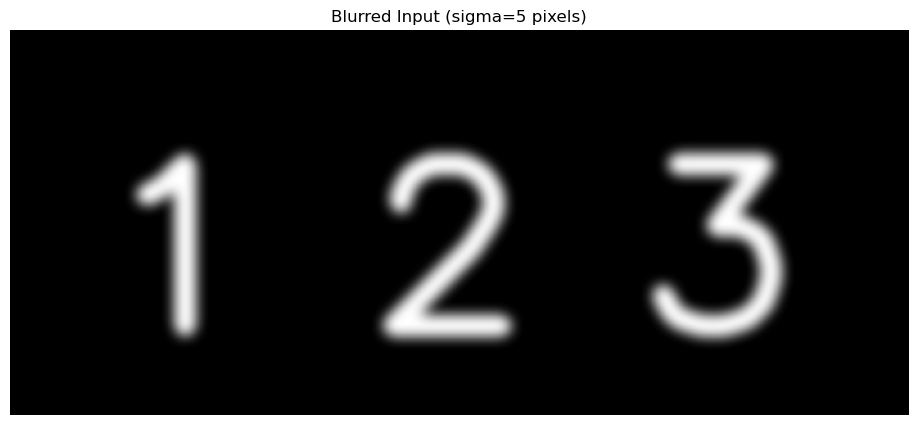

In [2]:
# 模拟输入图像的模糊，并转换为浮点数，避免后续 uint8 差分溢出或截断
blur = cv2.GaussianBlur(img, (21, 21), sigmaX=5)
input_img = blur.astype(np.float64) / 255.0

plt.figure(figsize=(12, 5))
plt.imshow(input_img, cmap="gray", vmin=0, vmax=1)
plt.title("Blurred Input (sigma=5 pixels)")
plt.axis("off")
plt.show()


## 2. 双尺度高斯滤波与差分

对同一个 `input_img` 分别使用窄核 σ=1.5 和宽核 σ=6.0，再计算“窄核结果 − 宽核结果”。
`(0, 0)` 让 OpenCV 根据 sigma 自动确定核大小。差分保留正、负响应，并使用对称色标显示。


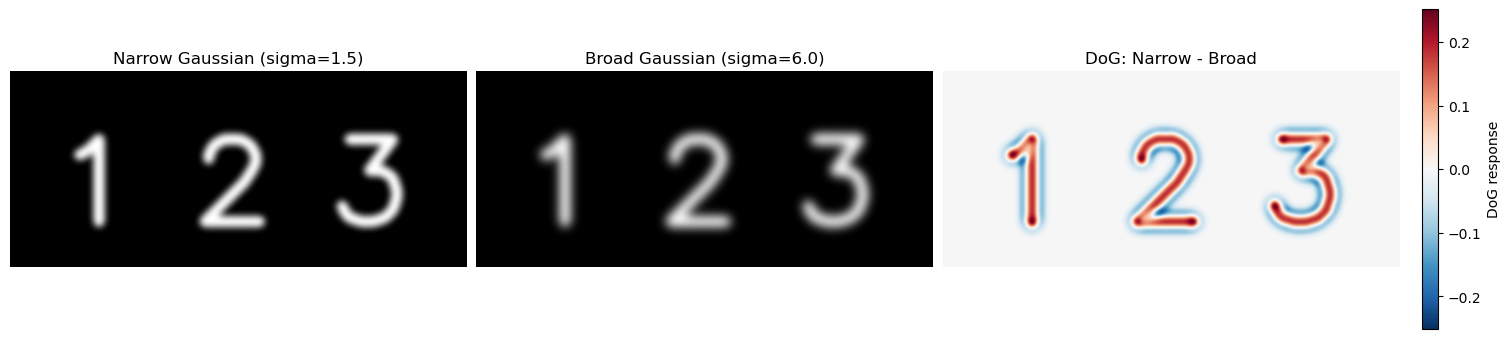

In [3]:
# 两次滤波都使用同一幅模糊输入，而不是在窄核结果上再次做宽核滤波
sigma_narrow = 1.5  # 单位：像素
sigma_broad = 6.0   # 宽核必须大于窄核

gaussian_img = cv2.GaussianBlur(input_img, (0, 0), sigmaX=sigma_narrow)
broad_img = cv2.GaussianBlur(input_img, (0, 0), sigmaX=sigma_broad)
dog = gaussian_img - broad_img

fig, axes = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)
axes[0].imshow(gaussian_img, cmap="gray", vmin=0, vmax=1)
axes[0].set_title(f"Narrow Gaussian (sigma={sigma_narrow})")
axes[1].imshow(broad_img, cmap="gray", vmin=0, vmax=1)
axes[1].set_title(f"Broad Gaussian (sigma={sigma_broad})")
dog_limit = max(float(np.abs(dog).max()), np.finfo(np.float64).eps)
dog_display = axes[2].imshow(dog, cmap="RdBu_r", vmin=-dog_limit, vmax=dog_limit)
axes[2].set_title("DoG: Narrow - Broad")
fig.colorbar(dog_display, ax=axes[2], shrink=0.65, label="DoG response")
for ax in axes:
    ax.axis("off")
plt.show()


## 3. 阈值分割与区域清理

保留 `DoG > 0.20 × DoG.max()` 的正响应，执行 3×3 闭运算连接小间隙，
再保留面积不少于 100 像素的所有连通区域并填洞。面积阈值可在下面调整。

这里包含三个数字，因此不采用仅保留最大连通区域的策略。
输出的连通区域数量也不代表通用的数字识别结果。


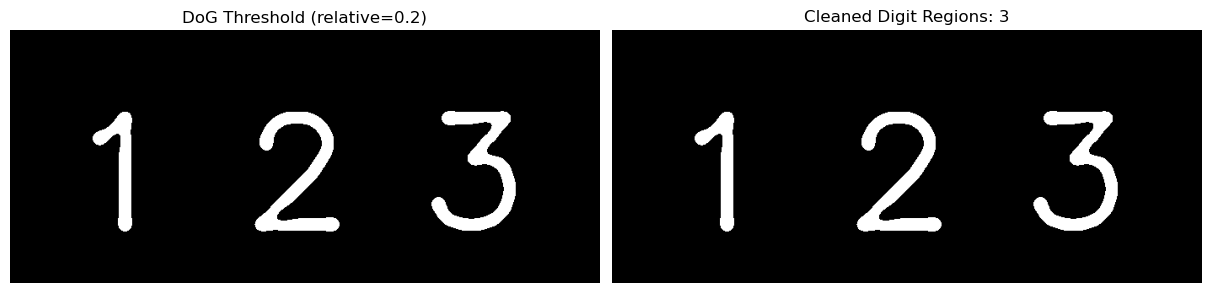

Number of retained connected regions: 3


In [4]:
threshold_rel = 0.20  # 相对 DoG 最大正响应的阈值
min_area = 100        # 最小连通区域面积，单位：像素

threshold_mask = (dog > threshold_rel * dog.max()).astype(np.uint8) * 255
kernel = np.ones((3, 3), dtype=np.uint8)
closed_mask = cv2.morphologyEx(threshold_mask, cv2.MORPH_CLOSE, kernel)

# 保留所有面积达标的连通区域，避免丢掉数字 1、2、3 中的任何一个
n_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
    closed_mask, connectivity=8
)
mask = np.zeros_like(closed_mask)
kept_regions = 0
for region_id in range(1, n_labels):  # 标签 0 是背景
    if stats[region_id, cv2.CC_STAT_AREA] >= min_area:
        mask[labels == region_id] = 255
        kept_regions += 1

# 从补零边框开始洪泛填充背景，再将未连通到外部的孔洞并入前景
padded_mask = np.pad(mask, 1, mode="constant")
flooded = padded_mask.copy()
cv2.floodFill(flooded, None, (0, 0), 255)
holes = cv2.bitwise_not(flooded)[1:-1, 1:-1]
mask = cv2.bitwise_or(mask, holes)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
axes[0].imshow(threshold_mask, cmap="gray", vmin=0, vmax=255)
axes[0].set_title(f"DoG Threshold (relative={threshold_rel})")
axes[1].imshow(mask, cmap="gray", vmin=0, vmax=255)
axes[1].set_title(f"Cleaned Digit Regions: {kept_regions}")
for ax in axes:
    ax.axis("off")
plt.show()

print("Number of retained connected regions:", kept_regions)
